# TSP Optimization with Simulated Annealing and Genetic Algorithms — Assignment Notebook

Works in **Jupyter** and **Google Colab**.

## Overview
You will solve the same TSP instance using **two heuristic optimization methods**:

1. **Simulated Annealing (SA)** with a 2-opt neighborhood  
2. **Genetic Algorithm (GA)** on **permutation tours** (a standard evolutionary approach for TSP)

The notebook provides:
- A reproducible TSP instance generator
- Tour utilities (length, validity)
- A 2-opt neighborhood operator
- Visualization helpers (tour plot + history plot)
- Baseline heuristic: nearest neighbor

## Tasks
### Task A — Simulated Annealing (SA)
Implement `simulated_annealing_tsp(...)`. Find sections with "TODO" to complete the implementations.

### Task B — Genetic Algorithm (GA)
Implement `genetic_algorithm_tsp(...)` plus helper functions:
- Tournament selection
- Order crossover (OX)
- Swap mutation
Find sections with "TODO" to complete the implementations.

## Deliverables
- Completed notebook (or exported `.py`) (find all TODOs and implement them)
- Write a technical report that includes:
  - Descriptions of the problem context, solutions (include important code snippets)
  - Experimental results, present the graphs, plots and data generated from the notebook based on your implementation.
    - SA parameters + best tour length
    - GA parameters + best tour length
    - Brief comparison: which worked better and why
    - More specifics can be found Part 6 below.
    - Optional work done in Part 7 below
  - Analysis of the experimental results.


---


In [ ]:
# If running in a fresh environment, uncomment as needed:
# !pip -q install matplotlib

import math
import random
import statistics
import matplotlib.pyplot as plt
import os
from dataclasses import dataclass
from typing import Dict, List, Optional, Tuple


## Part 1 — TSP utilities (provided)

In [ ]:
Point = Tuple[float, float]
Tour = List[int]

def make_cities(n: int = 40, seed: int = 7) -> List[Point]:
    # Reproducible 2D city coordinates in [0, 1]x[0, 1].
    rng = random.Random(seed)
    return [(rng.random(), rng.random()) for _ in range(n)]

def dist(a: Point, b: Point) -> float:
    dx = a[0] - b[0]
    dy = a[1] - b[1]
    return math.hypot(dx, dy)

def tour_length(cities: List[Point], tour: Tour) -> float:
    # Total length of a closed tour.
    n = len(tour)
    total = 0.0
    for i in range(n):
        total += dist(cities[tour[i]], cities[tour[(i + 1) % n]])
    return total

def is_valid_tour(tour: Tour, n: int) -> bool:
    return len(tour) == n and set(tour) == set(range(n))

def random_tour(n: int, rng: random.Random) -> Tour:
    t = list(range(n))
    rng.shuffle(t)
    return t

def nearest_neighbor_tour(cities: List[Point], start: int = 0) -> Tour:
    n = len(cities)
    unvisited = set(range(n))
    tour = [start]
    unvisited.remove(start)
    cur = start
    while unvisited:
        nxt = min(unvisited, key=lambda j: dist(cities[cur], cities[j]))
        tour.append(nxt)
        unvisited.remove(nxt)
        cur = nxt
    return tour


## Part 2 — Neighborhood operator (2-opt) (provided)

In [ ]:
def two_opt_swap(tour: Tour, i: int, k: int) -> Tour:
    return tour[:i] + list(reversed(tour[i:k + 1])) + tour[k + 1:]

def random_two_opt_neighbor(tour: Tour, rng: random.Random) -> Tour:
    n = len(tour)
    i = rng.randrange(0, n - 1)
    k = rng.randrange(i + 1, n)
    return two_opt_swap(tour, i, k)


## Part 3 — Visualization helpers (provided)

* You are encouraged to implement more variations of visualization.

In [ ]:
def _finish(name: str) -> None:
    plt.tight_layout()
    os.makedirs("figures", exist_ok=True)
    plt.savefig(os.path.join("figures", f"{name}.png"), dpi=140)
    plt.show()

def plot_tour(cities, tour, title="", fname="tour"):
    xs = [cities[i][0] for i in tour] + [cities[tour[0]][0]]
    ys = [cities[i][1] for i in tour] + [cities[tour[0]][1]]
    plt.figure(figsize=(6, 6))
    plt.plot(xs, ys, marker="o")
    plt.title(title)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.gca().set_aspect("equal", adjustable="box")
    _finish(fname)  

def plot_history(series, title, ylabel="Value", fname="history"):
    plt.figure(figsize=(7, 4))
    plt.plot(series)
    plt.title(title)
    plt.xlabel("Iteration")
    plt.ylabel(ylabel)
    _finish(fname) 

def plot_compare(sa_hist, ga_hist):
    plt.figure(figsize=(8, 4))
    plt.plot(sa_hist, label="SA best-so-far")
    plt.plot([i * (len(sa_hist) / max(1, len(ga_hist) - 1)) for i in range(len(ga_hist))],
             ga_hist, label="GA best-by-gen")
    plt.title("SA vs GA: Best tour length over time (scaled x-axis)")
    plt.xlabel("Progress (scaled)")
    plt.ylabel("Length")
    plt.legend()
    _finish("compare_scaled")   

## Part 4 — Baseline tour (nearest neighbor) (provided)

Nearest-neighbor length: 6.0214


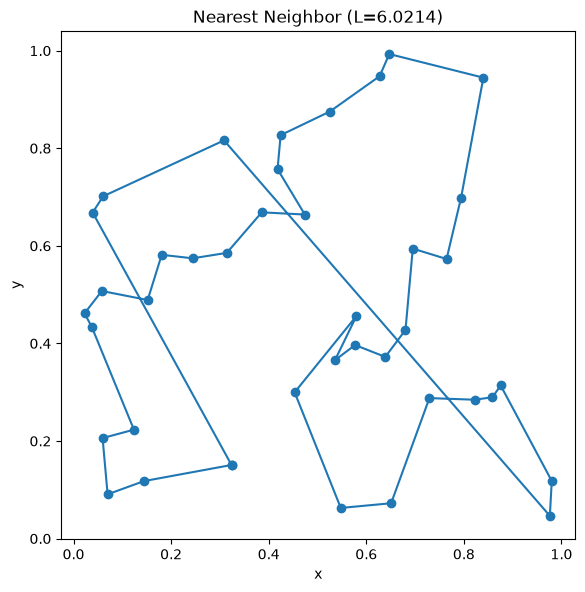

In [5]:
cities = make_cities(n=40, seed=7)

nn_tour = nearest_neighbor_tour(cities, start=0)
nn_len = tour_length(cities, nn_tour)
print(f"Nearest-neighbor length: {nn_len:.4f}")

plot_tour(cities, nn_tour, title=f"Nearest Neighbor (L={nn_len:.4f})")


# Part 5A — Code Skeleton: Simulated Annealing (SA)

Complete `simulated_annealing_tsp(...)`.

### SA acceptance rule
Let `delta = cand_len - cur_len`.
- If `delta <= 0`, accept.
- Else accept with probability `exp(-delta / T)`.

### Cooling schedule
Geometric cooling:
- `T = T * alpha` each iteration
- clamp `T = max(T, 1e-12)`


In [ ]:
@dataclass
class SAConfig:
    iters: int = 20_000
    t0: float = 0.2
    alpha: float = 0.9995
    seed: int = 123
    report_every: int = 2000

def simulated_annealing_tsp(cities, init_tour, cfg: SAConfig, stats: Optional[Dict[str, list]] = None):
    rng = random.Random(cfg.seed)
    n = len(cities)
    assert is_valid_tour(init_tour, n), "init_tour must be a valid permutation"

    cur_tour = init_tour[:]
    cur_len = tour_length(cities, cur_tour)

    best_tour = cur_tour[:]
    best_len = cur_len
    history = [best_len]

    T = cfg.t0

    if stats is not None:
        stats["accepted_deltas"] = []
        stats["rejected_deltas"] = []
        stats["accepted_uphill"] = []
        stats["cur_hist"] = [cur_len]
        stats["temp_hist"] = [T]
        stats["accept_flags"] = []

    for it in range(cfg.iters):
        cand_tour = random_two_opt_neighbor(cur_tour, rng)
        cand_len = tour_length(cities, cand_tour)
        delta = cand_len - cur_len

        accept = False
        if delta <= 0:
            accept = True
        else:
            accept = rng.random() < math.exp(-delta / T)

        if stats is not None:
            (stats["accepted_deltas"] if accept else stats["rejected_deltas"]).append(delta)
            if accept and delta > 0:
                stats["accepted_uphill"].append(delta)
            stats["accept_flags"].append(1 if accept else 0)

        if accept:
            cur_tour, cur_len = cand_tour, cand_len

        if cur_len < best_len:
            best_tour, best_len = cur_tour[:], cur_len

        history.append(best_len)

        T = max(T * cfg.alpha, 1e-12)

        if stats is not None:
            stats["cur_hist"].append(cur_len)
            stats["temp_hist"].append(T)

        if cfg.report_every and (it + 1) % cfg.report_every == 0:
            print(f"[SA] iter={it+1:6d}  T={T:.4g}  cur={cur_len:.4f}  best={best_len:.4f}")

    return best_tour, best_len, history

## Run SA (after you implement it)

[SA] iter=  2000  T=0.07356  cur=8.3800  best=6.0214
[SA] iter=  4000  T=0.02705  cur=6.5972  best=6.0214
[SA] iter=  6000  T=0.00995  cur=5.3139  best=5.3139
[SA] iter=  8000  T=0.003659  cur=5.0057  best=5.0057
[SA] iter= 10000  T=0.001346  cur=5.0057  best=5.0057
[SA] iter= 12000  T=0.000495  cur=5.0057  best=5.0057
[SA] iter= 14000  T=0.0001821  cur=5.0057  best=5.0057
[SA] iter= 16000  T=6.696e-05  cur=5.0057  best=5.0057
[SA] iter= 18000  T=2.463e-05  cur=5.0057  best=5.0057
[SA] iter= 20000  T=9.057e-06  cur=5.0057  best=5.0057
SA best length: 5.0057
SA improvement vs NN: 16.87%


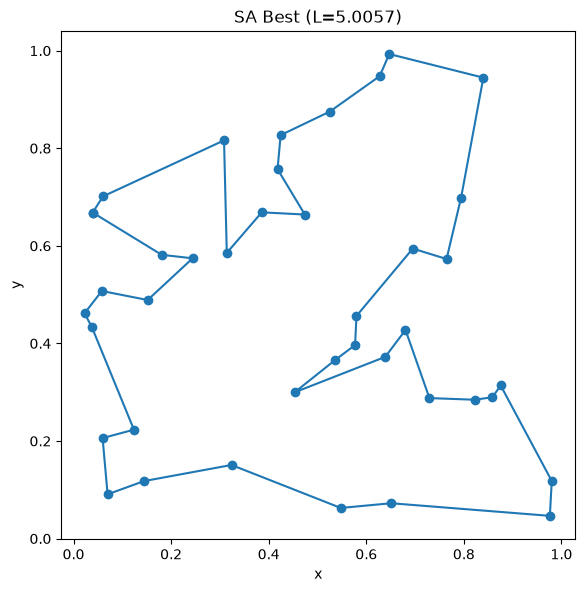

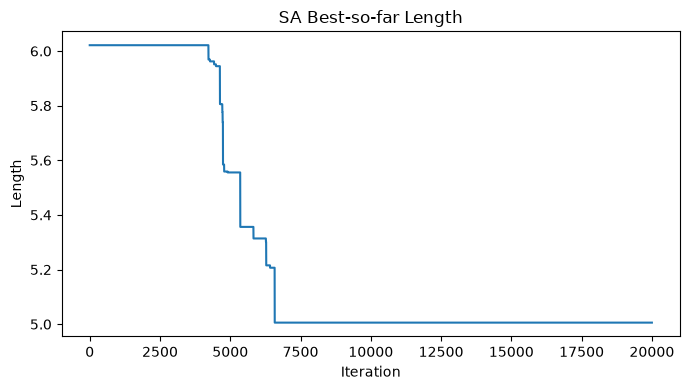

In [ ]:
sa_cfg = SAConfig(iters=20_000, t0=0.2, alpha=0.9995, seed=123, report_every=2000)
sa_stats: Dict[str, list] = {}
sa_best_tour, sa_best_len, sa_hist = simulated_annealing_tsp(
    cities, nn_tour[:], sa_cfg, stats=sa_stats)
sa_stats["best_hist"] = sa_hist

print(f"SA best length: {sa_best_len:.4f}")
print(f"SA improvement vs NN: {(nn_len - sa_best_len) / nn_len * 100:.2f}%")

assert is_valid_tour(sa_best_tour, len(cities))

plot_tour(cities, sa_best_tour, title=f"SA Best (L={sa_best_len:.4f})")
plot_history(sa_hist, title="SA Best-so-far Length", ylabel="Length")

# Part 5B — Code Skeleton: Genetic Algorithm (GA) for TSP

Implement a GA that evolves a population of permutation tours.

You will implement:
- `tournament_select(...)`
- `order_crossover_ox(...)` (Order Crossover)
- `mutate_swap(...)`
- `genetic_algorithm_tsp(...)`


In [ ]:
@dataclass
class GAConfig:
    pop_size: int = 200
    generations: int = 400
    tournament_k: int = 5
    crossover_rate: float = 0.9
    mutation_rate: float = 0.2
    elite_size: int = 5
    seed: int = 999
    report_every: int = 50
    mutation_op: str = "swap"
    
def tournament_select(pop: List[Tour], lengths: List[float], k: int, rng: random.Random) -> Tour:
    k = min(k, len(pop))
    contestants = rng.sample(range(len(pop)), k)
    winner = min(contestants, key=lambda i: lengths[i])
    return pop[winner][:]

def order_crossover_ox(parent1: Tour, parent2: Tour, rng: random.Random) -> Tour:
    n = len(parent1)
    a, b = sorted(rng.sample(range(n), 2))

    child: List[Optional[int]] = [None] * n
    child[a:b + 1] = parent1[a:b + 1]
    used = set(parent1[a:b + 1])

    p2_order = [parent2[(b + 1 + i) % n] for i in range(n)]
    fill = [c for c in p2_order if c not in used]

    pos = (b + 1) % n
    for c in fill:
        while child[pos] is not None:
            pos = (pos + 1) % n
        child[pos] = c
        pos = (pos + 1) % n

    return child

def mutate_swap(tour: Tour, rng: random.Random) -> Tour:
    t = tour[:]
    i, j = rng.sample(range(len(t)), 2)
    t[i], t[j] = t[j], t[i]
    return t

def mutate_inversion(tour: Tour, rng: random.Random) -> Tour:
    i, k = sorted(rng.sample(range(len(tour)), 2))
    return two_opt_swap(tour, i, k)


def mutate_2opt_greedy(tour: Tour, rng: random.Random, cities: List[Point]) -> Tour:
    cand = random_two_opt_neighbor(tour, rng)
    return cand if tour_length(cities, cand) < tour_length(cities, tour) else tour[:]

def _edge_set(tour: Tour) -> set:
    n = len(tour)
    return {frozenset((tour[i], tour[(i + 1) % n])) for i in range(n)}


def population_diversity(pop: List[Tour], rng: random.Random, n_pairs: int = 100
                         ) -> Tuple[float, float]:
    """Returns (unique_fraction, mean_edge_distance); 0 edge distance = identical."""
    n = len(pop[0])
    unique_fraction = len({tuple(t) for t in pop}) / len(pop)
    total = 0.0
    for _ in range(n_pairs):
        a, b = rng.sample(range(len(pop)), 2)
        shared = len(_edge_set(pop[a]) & _edge_set(pop[b]))
        total += 1.0 - shared / n
    return unique_fraction, total / n_pairs

def genetic_algorithm_tsp(cities: List[Point], init_seed_tours: List[Tour], cfg: GAConfig,
                          stats: Optional[Dict[str, list]] = None
                          ) -> Tuple[Tour, float, List[float]]:
    rng = random.Random(cfg.seed)
    n = len(cities)

    if cfg.mutation_op == "swap":
        mutate = lambda t: mutate_swap(t, rng)
    elif cfg.mutation_op == "inversion":
        mutate = lambda t: mutate_inversion(t, rng)
    elif cfg.mutation_op == "2opt":
        mutate = lambda t: mutate_2opt_greedy(t, rng, cities)
    else:
        raise ValueError(f"unknown mutation_op: {cfg.mutation_op}")

    pop: List[Tour] = []
    for t in init_seed_tours:
        assert is_valid_tour(t, n)
        pop.append(t[:])
    while len(pop) < cfg.pop_size:
        pop.append(random_tour(n, rng))

    lengths = [tour_length(cities, t) for t in pop]
    best_idx = min(range(len(pop)), key=lambda i: lengths[i])
    best_tour = pop[best_idx][:]
    best_len = lengths[best_idx]
    history = [best_len]

    div_rng = random.Random(cfg.seed + 1)
    if stats is not None:
        stats["avg_hist"] = [sum(lengths) / len(lengths)]
        stats["worst_hist"] = [max(lengths)]
        stats["std_hist"] = [statistics.pstdev(lengths)]
        u, d = population_diversity(pop, div_rng)
        stats["unique_frac"] = [u]
        stats["edge_dist"] = [d]
        stats["evals"] = [len(pop)]
    evals = len(pop)

    for gen in range(cfg.generations):
        elite_indices = sorted(range(len(pop)), key=lambda i: lengths[i])[: cfg.elite_size]
        next_pop = [pop[i][:] for i in elite_indices]

        while len(next_pop) < cfg.pop_size:
            p1 = tournament_select(pop, lengths, cfg.tournament_k, rng)
            p2 = tournament_select(pop, lengths, cfg.tournament_k, rng)

            if rng.random() < cfg.crossover_rate:
                child = order_crossover_ox(p1, p2, rng)
            else:
                child = p1[:]

            if rng.random() < cfg.mutation_rate:
                child = mutate(child)   # <<< CHANGED (was mutate_swap(child, rng))

            next_pop.append(child)

        evals += cfg.pop_size - cfg.elite_size   # <<< NEW

        pop = next_pop
        lengths = [tour_length(cities, t) for t in pop]

        gen_best_idx = min(range(len(pop)), key=lambda i: lengths[i])
        gen_best_len = lengths[gen_best_idx]
        if gen_best_len < best_len:
            best_len = gen_best_len
            best_tour = pop[gen_best_idx][:]

        history.append(best_len)

        if stats is not None:
            stats["avg_hist"].append(sum(lengths) / len(lengths))
            stats["worst_hist"].append(max(lengths))
            stats["std_hist"].append(statistics.pstdev(lengths))
            u, d = population_diversity(pop, div_rng)
            stats["unique_frac"].append(u)
            stats["edge_dist"].append(d)
            stats["evals"].append(evals)

        if cfg.report_every and (gen + 1) % cfg.report_every == 0:
            print(f"[GA] gen={gen+1:4d}  best={best_len:.4f}")

    assert is_valid_tour(best_tour, n)
    return best_tour, best_len, history

## Run GA

* After you implement TODOs above
* This is just for your reference, you can experiment with different paramesters

[GA] gen=  50  best=5.3672
[GA] gen= 100  best=5.3672
[GA] gen= 150  best=5.3672
[GA] gen= 200  best=5.3672
[GA] gen= 250  best=5.3672
[GA] gen= 300  best=5.3672
[GA] gen= 350  best=5.3672
[GA] gen= 400  best=5.3672
GA best length: 5.3672
GA improvement vs NN: 10.86%


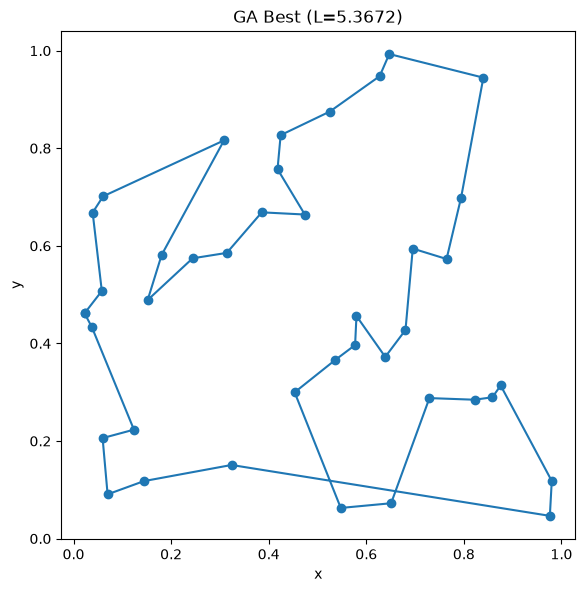

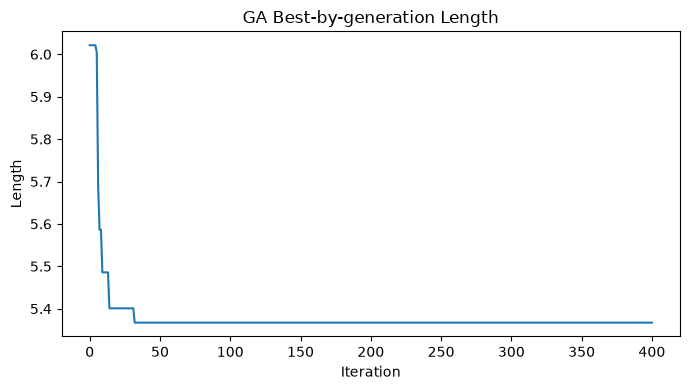

In [ ]:
ga_cfg = GAConfig(pop_size=200, generations=400, tournament_k=5, crossover_rate=0.9,
                  mutation_rate=0.2, elite_size=5, seed=999, report_every=50)
ga_stats: Dict[str, list] = {}
ga_best_tour, ga_best_len, ga_hist = genetic_algorithm_tsp(
    cities, init_seed_tours=[nn_tour], cfg=ga_cfg, stats=ga_stats)

print(f"GA best length: {ga_best_len:.4f}")
print(f"GA improvement vs NN: {(nn_len - ga_best_len) / nn_len * 100:.2f}%")

plot_tour(cities, ga_best_tour, title=f"GA Best (L={ga_best_len:.4f})", fname="tour_ga")
plot_history(ga_hist, title="GA Best-by-generation Length", ylabel="Length", fname="ga_best_history")

# Part 6 — Data Collection, Visualization and Comparison

* Instrument the code to collect the data and visualize them, including but not limited to
  * SA:
    * Track histogram of ΔE values for: Accepted moves and Rejected moves
  * GA:
    * Population average fitness
  * Cross SA and GA:
    * Plot SA best-so-far curve
    * Plot GA best-by-generation curve
    * Normalize x-axis by total evaluations
    * The above is already provided in the skeleton code. **Use them and/or with additional instrumentation of the code to collect and/or plot more data** to answer the following questions:
      * Which algorithm converged faster?
      * Which showed more variability?
      * Did SA escape local minima? Evidence?
      * Did GA lose diversity? Evidence?
* You are encouraged to come up with your own visualization and compare these two methods more extensively.

In [ ]:
def plot_sa_delta_histograms(stats: Dict[str, list]) -> None:
    """Histogram of ΔE for accepted vs rejected SA moves."""
    acc, rej = stats["accepted_deltas"], stats["rejected_deltas"]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].hist(acc, bins=60, color="tab:green", alpha=0.8)
    axes[0].axvline(0, color="k", lw=0.8)
    axes[0].set_title(f"Accepted moves ΔE (n={len(acc)})")
    axes[0].set_xlabel("ΔE = cand_len − cur_len")
    axes[0].set_ylabel("Count")
    axes[0].set_yscale("log")

    axes[1].hist(rej, bins=60, color="tab:red", alpha=0.8)
    axes[1].set_title(f"Rejected moves ΔE (n={len(rej)})")
    axes[1].set_xlabel("ΔE = cand_len − cur_len")
    axes[1].set_yscale("log")

    axes[2].hist(acc, bins=60, density=True, alpha=0.6, color="tab:green", label="accepted")
    axes[2].hist(rej, bins=60, density=True, alpha=0.6, color="tab:red", label="rejected")
    axes[2].set_title("Overlay (density)")
    axes[2].set_xlabel("ΔE")
    axes[2].legend()
    _finish("sa_delta_histograms")

def plot_sa_dynamics(stats: Dict[str, list], window: int = 500) -> None:
    """Current vs best length, temperature, and rolling acceptance rate."""
    fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
    axes[0].plot(stats["cur_hist"], lw=0.6, label="current length", alpha=0.8)
    axes[0].plot(stats["best_hist"], lw=1.4, label="best-so-far")
    axes[0].set_ylabel("Length")
    axes[0].set_title("SA dynamics (current length fluctuates -> uphill moves escape local minima)")
    axes[0].legend()

    axes[1].plot(stats["temp_hist"])
    axes[1].set_yscale("log")
    axes[1].set_ylabel("Temperature (log)")

    flags = stats["accept_flags"]
    rolling = [sum(flags[max(0, i - window):i + 1]) / (i - max(0, i - window) + 1)
               for i in range(len(flags))]
    axes[2].plot(rolling)
    axes[2].set_ylabel(f"Acceptance rate\n(rolling {window})")
    axes[2].set_xlabel("Iteration")
    _finish("sa_dynamics")

def plot_ga_population(ga_hist: List[float], ga_stats: Dict[str, list]) -> None:
    """Best / average / worst population fitness per generation."""
    gens = range(len(ga_hist))
    plt.figure(figsize=(8, 4.5))
    plt.plot(gens, ga_stats["worst_hist"], label="population worst", alpha=0.6)
    plt.plot(gens, ga_stats["avg_hist"], label="population average")
    plt.plot(gens, ga_hist, label="best-so-far", lw=2)
    plt.fill_between(gens,
                     [a - s for a, s in zip(ga_stats["avg_hist"], ga_stats["std_hist"])],
                     [a + s for a, s in zip(ga_stats["avg_hist"], ga_stats["std_hist"])],
                     alpha=0.2, label="avg ± 1 std")
    plt.title("GA population fitness per generation (tour length, lower is better)")
    plt.xlabel("Generation")
    plt.ylabel("Tour length")
    plt.legend()
    _finish("ga_population_fitness")

def plot_ga_diversity(ga_stats: Dict[str, list]) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(ga_stats["unique_frac"])
    axes[0].set_title("Fraction of unique tours in population")
    axes[0].set_xlabel("Generation")
    axes[0].set_ylim(0, 1.05)
    axes[1].plot(ga_stats["edge_dist"], color="tab:purple")
    axes[1].set_title("Mean pairwise edge distance (0 = identical)")
    axes[1].set_xlabel("Generation")
    axes[1].set_ylim(0, 1.05)
    _finish("ga_diversity")

def plot_compare_by_evals(sa_hist: List[float], ga_hist: List[float],
                          ga_evals: List[int], nn_len: float) -> None:
    """Best-so-far vs TOTAL tour-length evaluations (fair x-axis)."""
    sa_x = list(range(len(sa_hist)))
    plt.figure(figsize=(9, 4.8))
    plt.plot(sa_x, sa_hist, label="SA best-so-far")
    plt.plot(ga_evals, ga_hist, label="GA best-by-generation")
    plt.axhline(nn_len, color="gray", ls="--", lw=0.8, label="Nearest neighbor")
    plt.xscale("log")
    plt.title("SA vs GA: best length vs number of evaluations (log x)")
    plt.xlabel("Tour-length evaluations")
    plt.ylabel("Best length")
    plt.legend()
    _finish("compare_by_evals")

def evals_to_reach(hist: List[float], xs: List[int], target: float) -> Optional[int]:
    for h, x in zip(hist, xs):
        if h <= target:
            return x
    return None

In [ ]:
def multi_seed_study(cities, nn_tour, sa_cfg, ga_cfg, n_runs=10):
    """Run SA and GA with n_runs different seeds; return final best lengths."""
    sa_results, ga_results = [], []
    for s in range(n_runs):
        sa_c = SAConfig(**{**sa_cfg.__dict__, "seed": 1000 + s, "report_every": 0})
        ga_c = GAConfig(**{**ga_cfg.__dict__, "seed": 2000 + s, "report_every": 0})
        _, sl, _ = simulated_annealing_tsp(cities, nn_tour[:], sa_c)
        _, gl, _ = genetic_algorithm_tsp(cities, [nn_tour], ga_c)
        sa_results.append(sl)
        ga_results.append(gl)
    return sa_results, ga_results

def plot_variability(sa_res, ga_res, nn_len):
    plt.figure(figsize=(6, 4.5))
    try:
        plt.boxplot([sa_res, ga_res], tick_labels=["SA", "GA"], showmeans=True)
    except TypeError:
        plt.boxplot([sa_res, ga_res], labels=["SA", "GA"], showmeans=True)
    for i, r in enumerate([sa_res, ga_res], start=1):
        plt.scatter([i + random.uniform(-0.08, 0.08) for _ in r], r, alpha=0.6, s=18)
    plt.axhline(nn_len, color="gray", ls="--", lw=0.8, label="Nearest neighbor")
    plt.ylabel("Final best length")
    plt.title(f"Run-to-run variability ({len(sa_res)} seeds each)")
    plt.legend()
    _finish("variability_boxplot")

def summarize(label, res):
    print(f"  {label}: mean={statistics.mean(res):.4f}  std={statistics.pstdev(res):.4f}  "
          f"min={min(res):.4f}  max={max(res):.4f}")

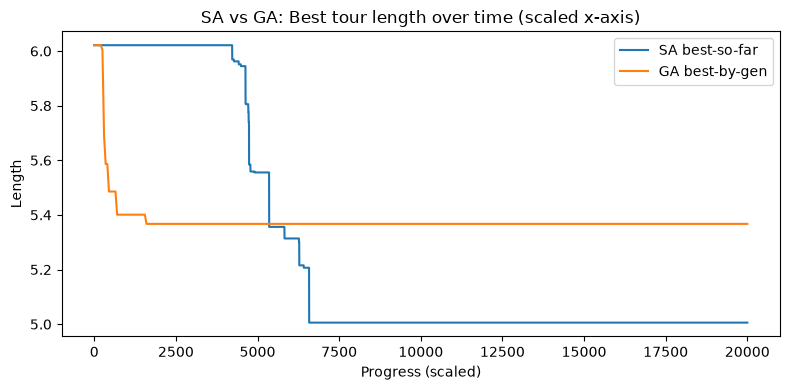

NN: 6.0214 | SA: 5.0057 | GA: 5.3672


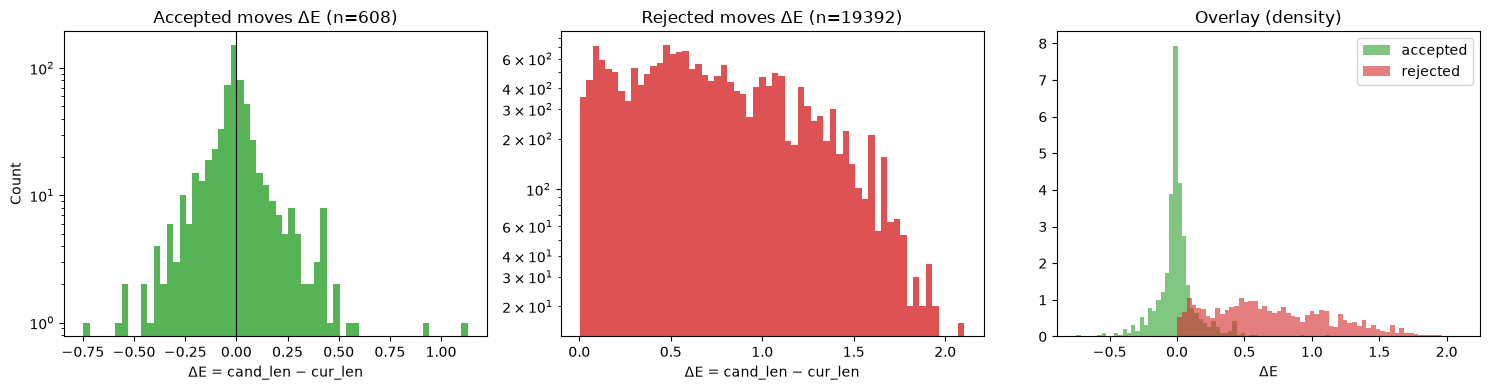

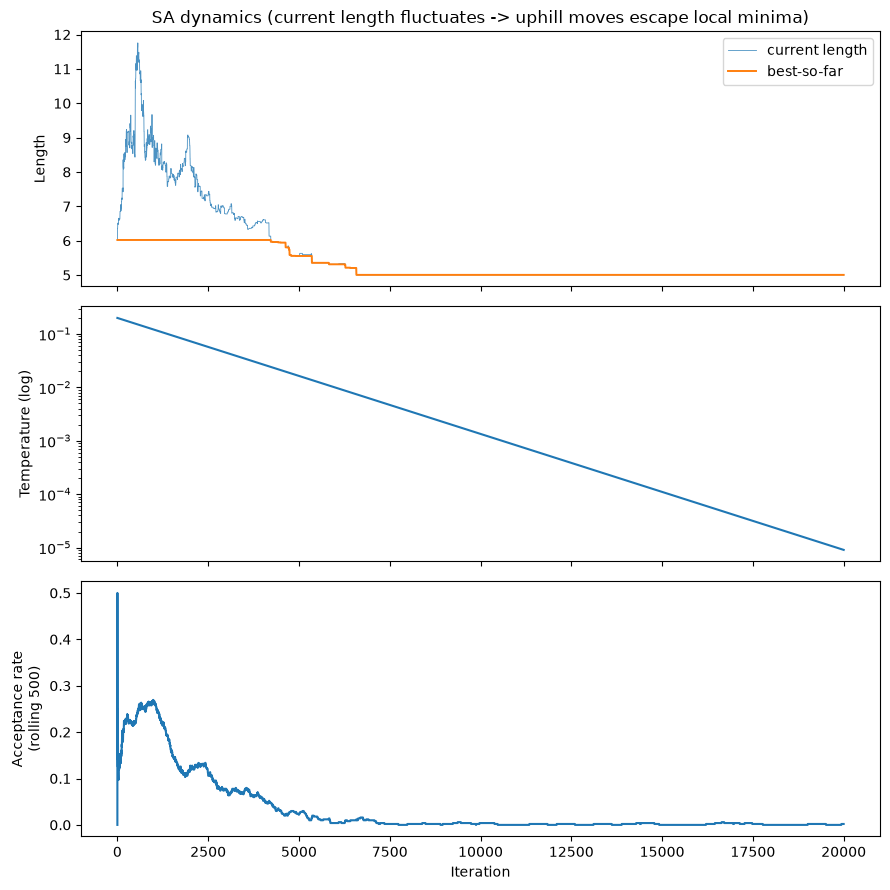

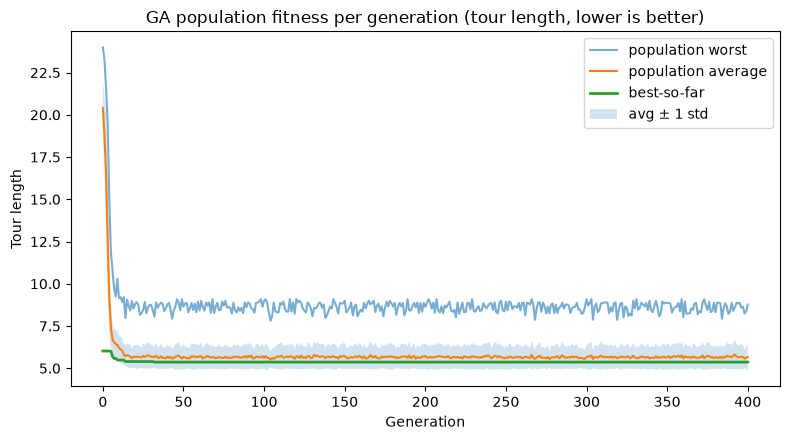

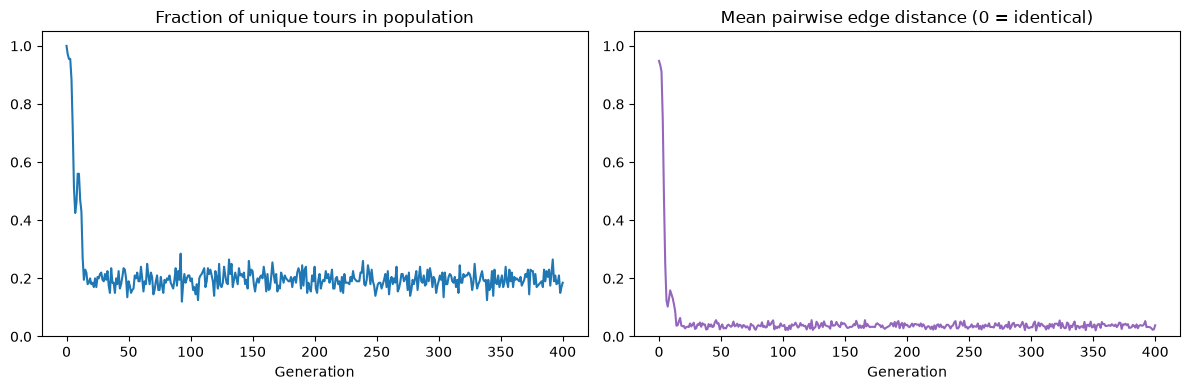

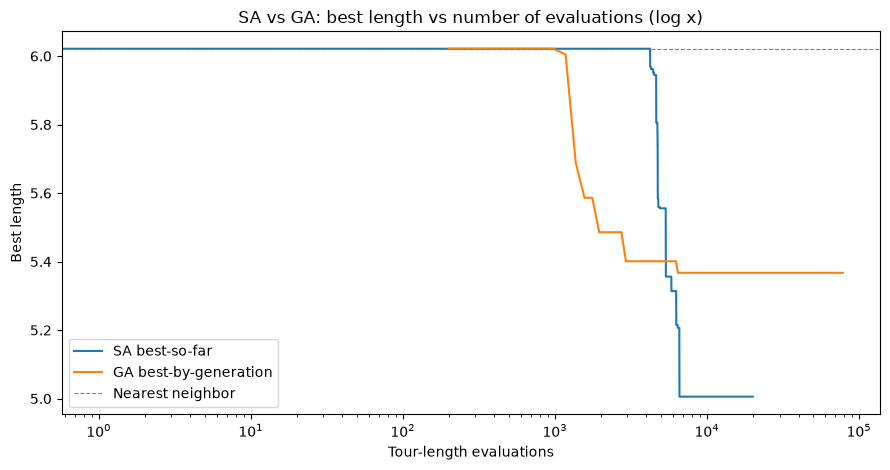

SA : 6277 evaluations
GA : None evaluations
accepted uphill moves: 283 (46.5% of accepted)
iterations where current length increased: 283
overall acceptance rate: 3.0%
acceptance rate in last 2000 iters: 0.1%
unique tours : 1.00 -> 0.18
edge distance: 0.948 -> 0.039
fitness std  : 1.6639 -> 0.7671
  SA: mean=4.9162  std=0.0618  min=4.8326  max=5.0248
  GA: mean=5.6363  std=0.3365  min=5.1546  max=5.9001


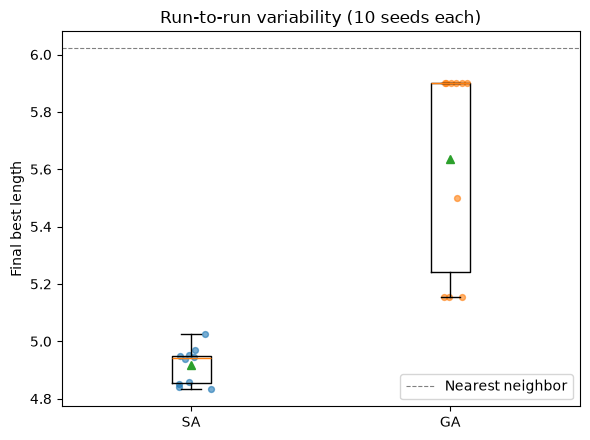

In [ ]:
plot_compare(sa_hist, ga_hist)
print(f"NN: {nn_len:.4f} | SA: {sa_best_len:.4f} | GA: {ga_best_len:.4f}")

plot_sa_delta_histograms(sa_stats)
plot_sa_dynamics(sa_stats)
plot_ga_population(ga_hist, ga_stats)
plot_ga_diversity(ga_stats)
plot_compare_by_evals(sa_hist, ga_hist, ga_stats["evals"], nn_len)

target = min(sa_best_len, ga_best_len) * 1.05
sa_x = list(range(len(sa_hist)))
print(f"SA : {evals_to_reach(sa_hist, sa_x, target)} evaluations")
print(f"GA : {evals_to_reach(ga_hist, ga_stats['evals'], target)} evaluations")

acc_up = sa_stats["accepted_uphill"]
cur = sa_stats["cur_hist"]
n_it = len(sa_stats["accept_flags"])
rises = sum(1 for i in range(1, len(cur)) if cur[i] > cur[i - 1])
print(f"accepted uphill moves: {len(acc_up)} "
      f"({len(acc_up) / max(1, sum(sa_stats['accept_flags'])) * 100:.1f}% of accepted)")
print(f"iterations where current length increased: {rises}")
print(f"overall acceptance rate: {sum(sa_stats['accept_flags']) / n_it * 100:.1f}%")
last = sa_stats["accept_flags"][-2000:]
print(f"acceptance rate in last 2000 iters: {sum(last) / len(last) * 100:.1f}%")

print(f"unique tours : {ga_stats['unique_frac'][0]:.2f} -> {ga_stats['unique_frac'][-1]:.2f}")
print(f"edge distance: {ga_stats['edge_dist'][0]:.3f} -> {ga_stats['edge_dist'][-1]:.3f}")
print(f"fitness std  : {ga_stats['std_hist'][0]:.4f} -> {ga_stats['std_hist'][-1]:.4f}")

sa_res, ga_res = multi_seed_study(cities, nn_tour, sa_cfg, ga_cfg, n_runs=10)
summarize("SA", sa_res)
summarize("GA", ga_res)
plot_variability(sa_res, ga_res, nn_len)

# Part 7: Optional Task

The optional extra work will be considered for extra credit.

- Try different crossover and/or mutation operations in GA and see if you can improve the performance.

- If you identify other interesting analytics of intermediate data that shows how the algorithms are performing, you can carry out the experiements in this section.

- Document your effort in this section **and** the technical report mentioned above in the Deliverables.



  GA mutation=swap      mean=5.3432  best=5.1546  std=0.1544
  GA mutation=inversion mean=4.9322  best=4.8637  std=0.0967
  GA mutation=2opt      mean=4.9189  best=4.8326  std=0.0907


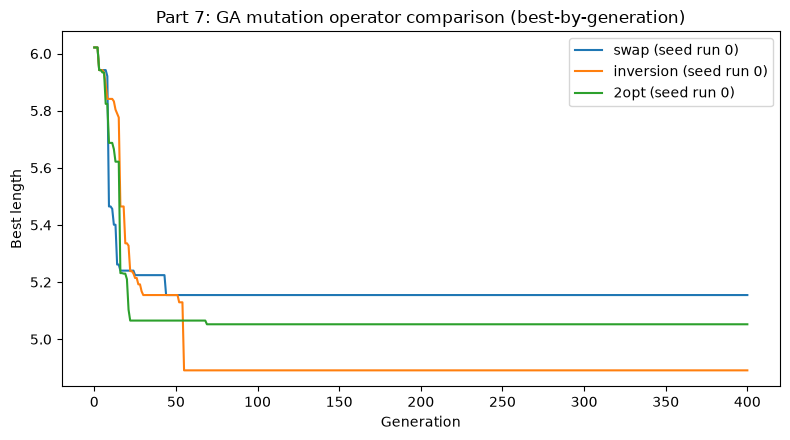

  SA alpha=0.999   mean=5.0008  best=4.8424  std=0.1521
  SA alpha=0.9995  mean=4.9625  best=4.8326  std=0.1105
  SA alpha=0.9999  mean=4.9700  best=4.8438  std=0.1314


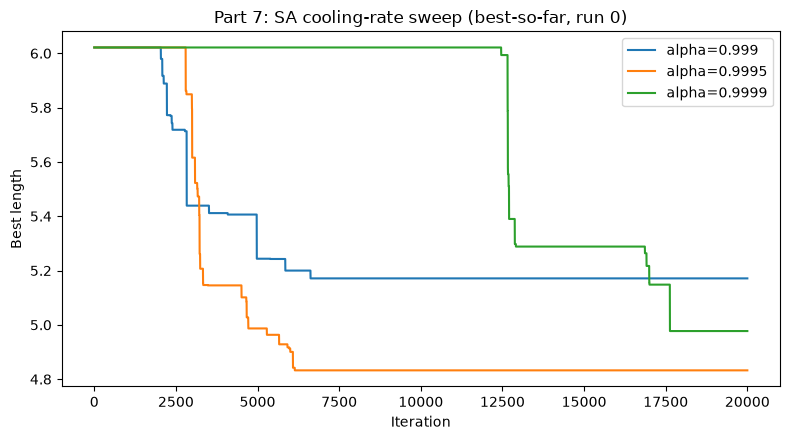

{0.999: [5.171194025886363,
  4.845517667531545,
  4.8424267915246775,
  4.956139792905686,
  5.188916136246325],
 0.9995: [4.832565987814186,
  4.938594182854034,
  5.168117928978478,
  4.934748527733435,
  4.938594182854033],
 0.9999: [4.97728015334292,
  4.930318164150785,
  5.216881798772174,
  4.881961355589378,
  4.843757280620853]}

In [ ]:
def experiment_mutation_operators(cities: List[Point], nn_tour: Tour, base: GAConfig,
                                  n_runs: int = 5) -> Dict[str, List[float]]:
    """Compare swap / inversion / greedy-2opt mutation (same budget, several seeds)."""
    results: Dict[str, List[float]] = {}
    histories: Dict[str, List[float]] = {}
    for op in ("swap", "inversion", "2opt"):
        res = []
        for s in range(n_runs):
            cfg = GAConfig(**{**base.__dict__, "mutation_op": op, "seed": 3000 + s,
                              "report_every": 0})
            _, l, h = genetic_algorithm_tsp(cities, [nn_tour], cfg)
            res.append(l)
            if s == 0:
                histories[op] = h
        results[op] = res
        print(f"  GA mutation={op:9s} mean={statistics.mean(res):.4f}  "
              f"best={min(res):.4f}  std={statistics.pstdev(res):.4f}")

    plt.figure(figsize=(8, 4.5))
    for op, h in histories.items():
        plt.plot(h, label=f"{op} (seed run 0)")
    plt.title("Part 7: GA mutation operator comparison (best-by-generation)")
    plt.xlabel("Generation")
    plt.ylabel("Best length")
    plt.legend()
    _finish("part7_ga_mutation_comparison")
    return results

def experiment_sa_cooling(cities: List[Point], nn_tour: Tour, n_runs: int = 5
                          ) -> Dict[float, List[float]]:
    """Sweep SA cooling rate alpha at a FIXED iteration budget (t0 fixed)."""
    results: Dict[float, List[float]] = {}
    plt.figure(figsize=(8, 4.5))
    for alpha in (0.999, 0.9995, 0.9999):
        res = []
        for s in range(n_runs):
            cfg = SAConfig(iters=20_000, t0=0.2, alpha=alpha, seed=4000 + s, report_every=0)
            _, l, h = simulated_annealing_tsp(cities, nn_tour[:], cfg)
            res.append(l)
            if s == 0:
                plt.plot(h, label=f"alpha={alpha}")
        results[alpha] = res
        print(f"  SA alpha={alpha:<7} mean={statistics.mean(res):.4f}  "
              f"best={min(res):.4f}  std={statistics.pstdev(res):.4f}")
    plt.title("Part 7: SA cooling-rate sweep (best-so-far, run 0)")
    plt.xlabel("Iteration")
    plt.ylabel("Best length")
    plt.legend()
    _finish("part7_sa_cooling_sweep")
    return results

experiment_mutation_operators(cities, nn_tour, ga_cfg, n_runs=5)
experiment_sa_cooling(cities, nn_tour, n_runs=5)

## Example of how to check your work

In [ ]:
def grade_check(nn_len: float, method_len: float, min_improvement_pct: float = 10.0, label: str = "Method") -> None:
    improvement = (nn_len - method_len) / nn_len * 100.0
    print(f"{label} length: {method_len:.4f} | Improvement vs NN: {improvement:.2f}%")
    assert improvement >= min_improvement_pct, (
        f"{label} improvement {improvement:.2f}% is below required {min_improvement_pct:.2f}%"
    )
    print(f"✅ {label} passed improvement threshold!")